# 01 · EDA: is there anything worth targeting?

An uplift model only makes sense if two things are true:

1. **The experiment is trustworthy**: randomisation worked, so treated and control are comparable.
2. **The treatment effect is heterogeneous**: some customers react much more than others. If everyone reacted the same way, the best policy would be "send to all or to nobody" and no model would be needed.

This notebook checks both on **Hillstrom** (64k customers, email campaign) and **Criteo** (14M users, ad campaign).
All EDA uses the **training split only**, so the val and test sets are never seen before model evaluation.

> All logic lives in `src/uplift/` and is unit-tested. This notebook only calls it and plots the results.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from uplift.config import load_config
from uplift.data.datasets import CRITEO_SPEC, HILLSTROM_SPEC
from uplift.data.eda import effect_by_segment, outcome_rates_by_arm
from uplift.data.split import load_split
from uplift.data.stats import average_treatment_effect, covariate_balance
from uplift.viz import apply_style, plot_balance, plot_effect_forest, plot_rates_by_arm

apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
cfg = load_config()
FIG_DIR = cfg.paths.reports_dir / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## Part 1 · Hillstrom email experiment

### 1.1 Did the experiment run correctly?
Results of `make validate` (schema, row count, sample-ratio mismatch, leakage, covariate balance) on the full raw data:

In [2]:
def validation_table(name):
    r = json.loads((cfg.paths.reports_dir / "validation" / f"{name}.json").read_text())
    rows = {k: "PASS" if v["passed"] else "FAIL" for k, v in r["checks"].items()}
    rows["srm p-value"] = f"{r['checks']['srm']['p_value']:.3f}"
    rows["max |SMD|"] = f"{r['checks']['balance']['max_abs_smd']:.4f}"
    return pd.Series(rows, name=name)


pd.concat([validation_table("hillstrom"), validation_table("criteo")], axis=1)

,hillstrom,criteo
schema,PASS,PASS
row_count,PASS,PASS
srm,PASS,PASS
leakage,PASS,PASS
balance,PASS,PASS
srm p-value,0.904,0.999
max |SMD|,0.0088,0.0488


train rows: 44,800


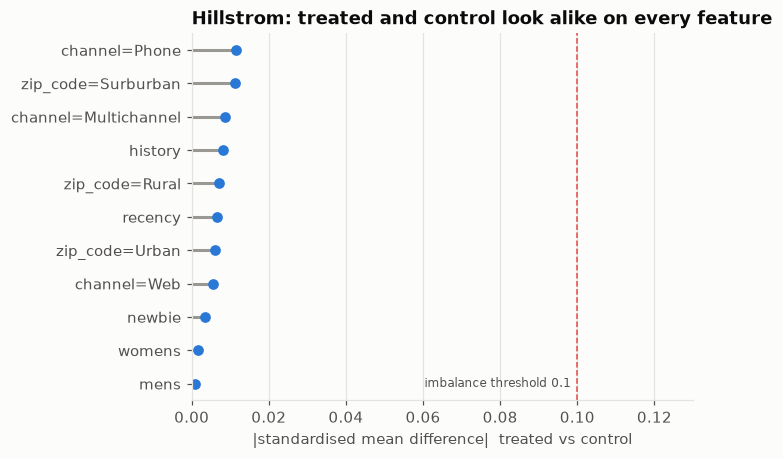

In [3]:
h = load_split("hillstrom", "train", cfg.paths.processed_dir)
print(f"train rows: {len(h):,}")
save(
    plot_balance(
        covariate_balance(h, HILLSTROM_SPEC.features, "treatment"),
        "Hillstrom: treated and control look alike on every feature",
    ),
    "hillstrom_balance",
)

### 1.2 What did the emails do on average?

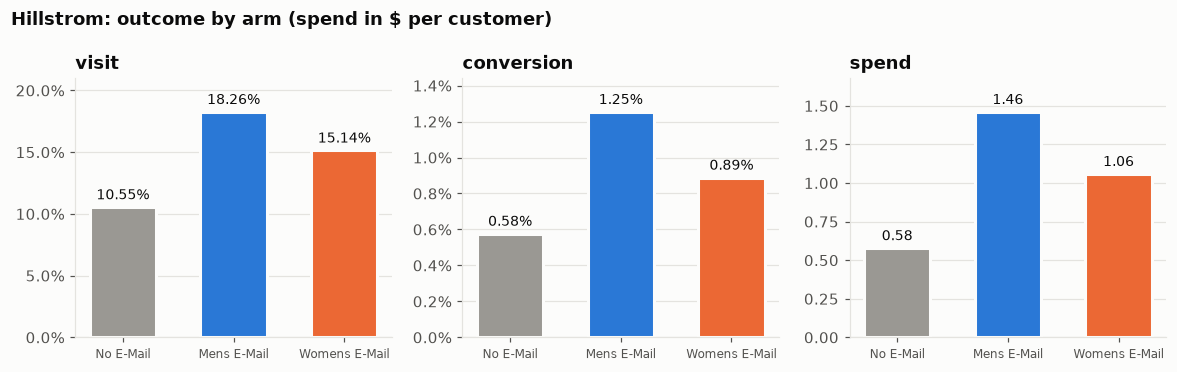

,visit,conversion,spend,n
segment,,,,
Mens E-Mail,0.1826,0.0125,1.4608,14915
No E-Mail,0.1055,0.0058,0.5785,14914
Womens E-Mail,0.1514,0.0089,1.0592,14971


In [4]:
rates = outcome_rates_by_arm(h, HILLSTROM_SPEC)
save(
    plot_rates_by_arm(
        rates,
        ["visit", "conversion", "spend"],
        "Hillstrom: outcome by arm (spend in $ per customer)",
    ),
    "hillstrom_rates",
)
rates

In [5]:
rows = []
for outcome in HILLSTROM_SPEC.outcomes:
    for arm in ["Mens E-Mail", "Womens E-Mail"]:
        sub = h[h["segment"].isin([arm, "No E-Mail"])]
        e = average_treatment_effect(sub[outcome], sub["segment"] == arm)
        rows.append(
            {
                "outcome": outcome,
                "arm": arm,
                "ate": e.ate,
                "ci_low": e.ci_low,
                "ci_high": e.ci_high,
                "relative_lift": e.relative_lift,
                "p_value": e.p_value,
            }
        )
pd.DataFrame(rows)

,outcome,arm,ate,ci_low,ci_high,relative_lift,p_value
0,visit,Mens E-Mail,0.0772,0.0692,0.0851,0.7316,0.0000
1,visit,Womens E-Mail,0.0460,0.0384,0.0535,0.4357,0.0000
2,conversion,Mens E-Mail,0.0068,0.0046,0.0089,1.1743,0.0000
3,conversion,Womens E-Mail,0.0031,0.0012,0.0051,0.5406,0.0016
4,spend,Mens E-Mail,0.8823,0.5469,1.2177,1.5252,0.0000
5,spend,Womens E-Mail,0.4807,0.1936,0.7677,0.8309,0.0010


Both emails work on average: the men's email lifts visits by about 7.7 pp and the women's email by about 4.5 pp, matching the published results.
An average effect, though, hides *who* is moved by the email.

### 1.3 Does the effect differ between customers? (the case for an uplift model)
Each point is the visit uplift inside one customer segment, with its 95% CI.

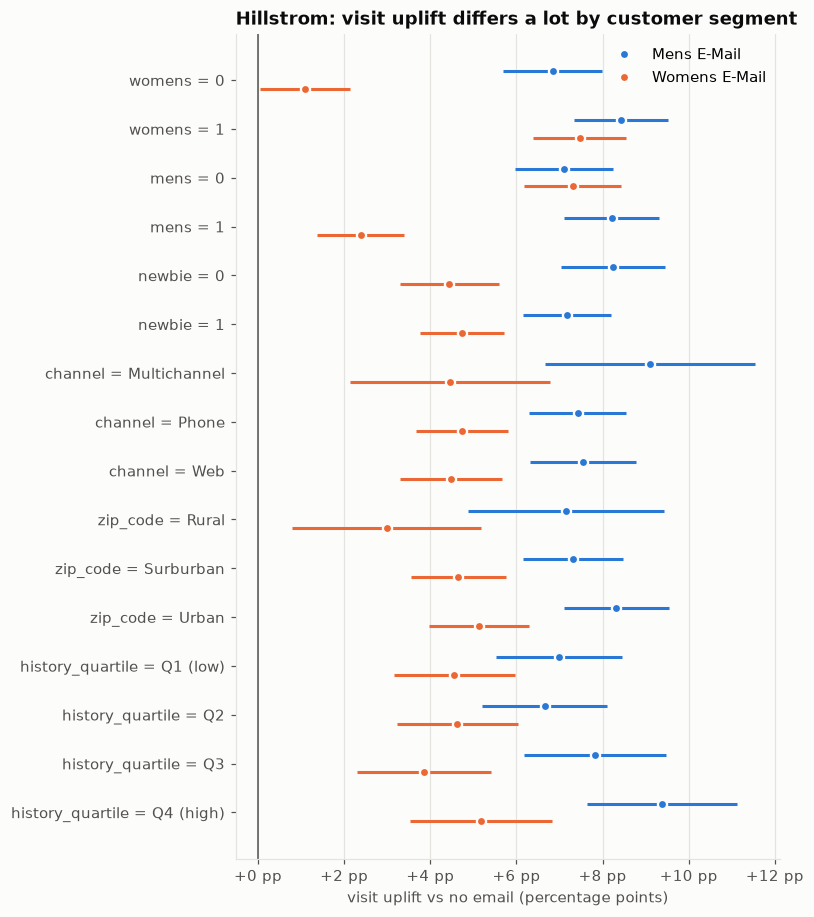

In [6]:
h["history_quartile"] = pd.qcut(h["history"], 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
segments = ["womens", "mens", "newbie", "channel", "zip_code", "history_quartile"]
effects = effect_by_segment(h, HILLSTROM_SPEC, segments, "visit")
save(
    plot_effect_forest(
        effects,
        "Hillstrom: visit uplift differs a lot by customer segment",
        "visit uplift vs no email (percentage points)",
    ),
    "hillstrom_uplift_by_segment",
)

In [7]:
(
    effects.pivot_table(index=["feature", "level"], columns="arm", values="ate").loc[
        ["womens", "mens"]
    ]
)

arm            Mens E-Mail  Womens E-Mail
feature level                            
womens  0           0.0684         0.0110
        1           0.0843         0.0747
mens    0           0.0709         0.0730
        1           0.0821         0.0238

**What this shows:**

- The **women's email** barely moves customers who have never bought women's products (`womens = 0`, about +1 pp, CI close to 0), but lifts past women's-wear buyers by about +7.5 pp. Those barely-moved customers are about 45% of the base, so blanket sending wastes almost half the sends.
- The **men's email** works for both groups, more strongly for past men's buyers and high-history customers.
- For past men's buyers (`mens = 1`), the women's email lifts visits by only +2.4 pp, compared with +8.2 pp for the men's email. **Which** coupon a user gets matters as much as **whether** they get one (the multi-treatment stretch goal).

This heterogeneity is what an uplift model learns at the individual level, using all features together instead of one at a time.

### 1.4 How much signal is there? (choosing the training target)

In [8]:
positives = h.groupby("segment", observed=True)[["visit", "conversion"]].sum()
positives.loc["total"] = positives.sum()
positives

,visit,conversion
segment,,
Mens E-Mail,2724,187
No E-Mail,1573,86
Womens E-Mail,2267,133
total,6564,406


Conversions are scarce: only a few hundred in training, split across three arms. An uplift model estimates a *difference* between two noisy rates, so conversion-based model selection would mostly measure noise.

**Decision:** train and select uplift models on **visit** (about 16× more positives: 6,564 vs 406) and use **conversion and spend** to compute business value in the policy simulator.

## Part 2 · Criteo ad experiment (10% stratified dev sample)

Criteo's 12 features are anonymised (`f0`–`f11`), so segment *stories* are not possible here. The dataset's job in this project is scale.

train rows: 978,571  (full dataset: 13,979,592)


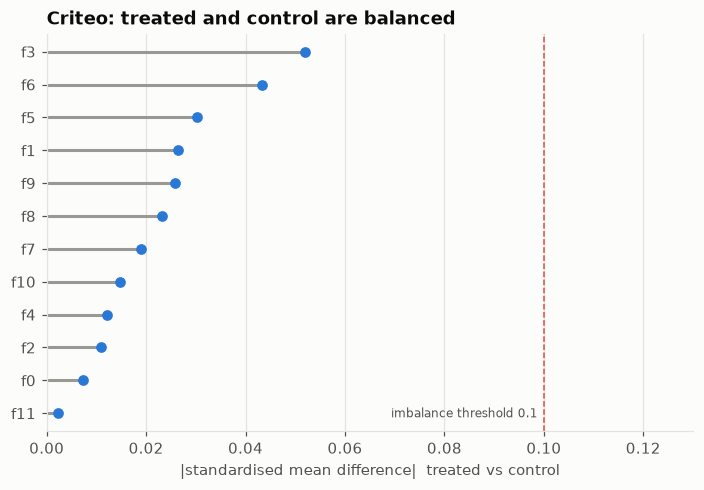

In [9]:
c = load_split("criteo", "train", cfg.paths.processed_dir)
print(f"train rows: {len(c):,}  (full dataset: {CRITEO_SPEC.expected_rows:,})")
save(
    plot_balance(
        covariate_balance(c, CRITEO_SPEC.features, "treatment"),
        "Criteo: treated and control are balanced",
    ),
    "criteo_balance",
)

In [10]:
rows = []
for outcome in CRITEO_SPEC.outcomes:
    e = average_treatment_effect(c[outcome], c["treatment"])
    rows.append(
        {
            "outcome": outcome,
            "control_rate": e.control_mean,
            "treated_rate": e.treated_mean,
            "ate": e.ate,
            "ci_low": e.ci_low,
            "ci_high": e.ci_high,
            "relative_lift": e.relative_lift,
        }
    )
pd.DataFrame(rows)

,outcome,control_rate,treated_rate,ate,ci_low,ci_high,relative_lift
0,visit,0.0385,0.0489,0.0104,0.0093,0.0115,0.2706
1,conversion,0.0019,0.0031,0.0012,0.0009,0.0014,0.5963


In [11]:
c.groupby("treatment")[["visit", "conversion"]].agg(["sum", "mean"])

visit        conversion       
             sum   mean        sum   mean
treatment                                
0           5645 0.0385        284 0.0019
1          40643 0.0489       2569 0.0031

**What this shows:**

- The ads work: visits rise by about 1 pp (+27% relative) and conversions by about 0.1 pp (+60% relative).
- The control arm is only 15% of users, and conversion is about 0.3%. The control group of a 10% sample has only a few hundred conversions. This is why
  - the **X-learner** and **DR-learner** (which handle unbalanced arms) are in the model set, and
  - every Qini comparison gets **bootstrap confidence intervals**.
- `exposure` is recorded after treatment and is blocked by the leakage guard.

## Decisions carried into Phase 2

| Decision | Choice |
|---|---|
| Hillstrom treatment | Binary *any email vs none* for the main models; per-arm labels kept for multi-treatment |
| Training / selection target | `visit` (Hillstrom and Criteo) |
| Business value | `conversion` and `spend` in the policy simulator |
| Features | Hillstrom: recency, history, mens, womens, zip_code, newbie, channel. Criteo: f0–f11 |
| Evaluation data | Untouched until final evaluation; all EDA above used `train` only |